In [1]:
import sys
import pandas as pd
import numpy as np
import sklearn
import matplotlib

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
pandas: 3.1.0
numpy: 2.5.4
sklearn: 1.9.1
matplotlib: 3.11.2


In [2]:
import pandas as pd

df = pd.read_csv('../data/raw/german.data', sep=' ', header=None)
print("Shape:", df.shape)
print(df.head())
print(df[20].value_counts())

Shape: (1000, 21)
    0   1    2    3     4    5    6   7    8     9   ...    11  12    13  \
0  A11   6  A34  A43  1169  A65  A75   4  A93  A101  ...  A121  67  A143   
1  A12  48  A32  A43  5951  A61  A73   2  A92  A101  ...  A121  22  A143   
2  A14  12  A34  A46  2096  A61  A74   2  A93  A101  ...  A121  49  A143   
3  A11  42  A32  A42  7882  A61  A74   2  A93  A103  ...  A122  45  A143   
4  A11  24  A33  A40  4870  A61  A73   3  A93  A101  ...  A124  53  A143   

     14 15    16 17    18    19 20  
0  A152  2  A173  1  A192  A201  1  
1  A152  1  A173  1  A191  A201  2  
2  A152  1  A172  2  A191  A201  1  
3  A153  1  A173  2  A191  A201  1  
4  A153  2  A173  2  A191  A201  2  

[5 rows x 21 columns]
20
1    700
2    300
Name: count, dtype: int64


In [1]:
import pandas as pd

columns = ['checking_status', 'duration', 'credit_history', 'purpose',
           'credit_amount', 'savings_status', 'employment', 'installment_commitment',
           'personal_status', 'other_parties', 'residence_since', 'property_magnitude',
           'age', 'other_payment_plans', 'housing', 'existing_credits',
           'job', 'num_dependents', 'own_telephone', 'foreign_worker', 'credit_risk']

df = pd.read_csv('../data/raw/german.data', sep=' ', header=None, names=columns)
print("Shape:", df.shape)
print("\n5 dòng đầu:")
print(df.head())
print("\nPhân bố nhãn:")
print(df['credit_risk'].value_counts())
print("\nKiểu dữ liệu từng cột:")
print(df.dtypes)

Shape: (1000, 21)

5 dòng đầu:
  checking_status  duration credit_history purpose  credit_amount  \
0             A11         6            A34     A43           1169   
1             A12        48            A32     A43           5951   
2             A14        12            A34     A46           2096   
3             A11        42            A32     A42           7882   
4             A11        24            A33     A40           4870   

  savings_status employment  installment_commitment personal_status  \
0            A65        A75                       4             A93   
1            A61        A73                       2             A92   
2            A61        A74                       2             A93   
3            A61        A74                       2             A93   
4            A61        A73                       3             A93   

  other_parties  ...  property_magnitude age  other_payment_plans housing  \
0          A101  ...                A121  67      

In [2]:
# Map mã sang nhãn có nghĩa (dựa trên german.doc)
checking_map = {'A11': '< 0 DM', 'A12': '0-200 DM', 'A13': '>= 200 DM', 'A14': 'no account'}
credit_history_map = {'A30': 'no credits/all paid', 'A31': 'all paid (this bank)',
                      'A32': 'existing paid till now', 'A33': 'delay in past',
                      'A34': 'critical/other credits'}
purpose_map = {'A40': 'new car', 'A41': 'used car', 'A42': 'furniture/equipment',
               'A43': 'radio/TV', 'A44': 'domestic appliances', 'A45': 'repairs',
               'A46': 'education', 'A47': 'vacation', 'A48': 'retraining',
               'A49': 'business', 'A410': 'others'}
savings_map = {'A61': '< 100 DM', 'A62': '100-500 DM', 'A63': '500-1000 DM',
               'A64': '>= 1000 DM', 'A65': 'unknown/no savings'}
employment_map = {'A71': 'unemployed', 'A72': '< 1 year', 'A73': '1-4 years',
                  'A74': '4-7 years', 'A75': '>= 7 years'}
personal_status_map = {'A91': 'male divorced/separated', 'A92': 'female divorced/separated/married',
                       'A93': 'male single', 'A94': 'male married/widowed', 'A95': 'female single'}
other_parties_map = {'A101': 'none', 'A102': 'co-applicant', 'A103': 'guarantor'}
property_map = {'A121': 'real estate', 'A122': 'building society/life insurance',
                'A123': 'car or other', 'A124': 'unknown/no property'}
other_plans_map = {'A141': 'bank', 'A142': 'stores', 'A143': 'none'}
housing_map = {'A151': 'rent', 'A152': 'own', 'A153': 'for free'}
job_map = {'A171': 'unemployed/unskilled non-resident', 'A172': 'unskilled resident',
           'A173': 'skilled employee/official', 'A174': 'management/self-employed'}
telephone_map = {'A191': 'none', 'A192': 'yes registered'}
foreign_worker_map = {'A201': 'yes', 'A202': 'no'}

df['checking_status_label'] = df['checking_status'].map(checking_map)
df['credit_history_label'] = df['credit_history'].map(credit_history_map)
df['purpose_label'] = df['purpose'].map(purpose_map)
df['savings_label'] = df['savings_status'].map(savings_map)
df['employment_label'] = df['employment'].map(employment_map)
df['personal_status_label'] = df['personal_status'].map(personal_status_map)
df['other_parties_label'] = df['other_parties'].map(other_parties_map)
df['property_label'] = df['property_magnitude'].map(property_map)
df['other_plans_label'] = df['other_payment_plans'].map(other_plans_map)
df['housing_label'] = df['housing'].map(housing_map)
df['job_label'] = df['job'].map(job_map)
df['telephone_label'] = df['own_telephone'].map(telephone_map)
df['foreign_worker_label'] = df['foreign_worker'].map(foreign_worker_map)
df['credit_risk_label'] = df['credit_risk'].map({1: 'Good', 2: 'Bad'})

# Kiểm tra map có bị NaN không (nếu có, nghĩa là có mã chưa map)
print("Số NaN ở các cột label:")
print(df[[c for c in df.columns if c.endswith('_label')]].isna().sum())

# Lưu file sạch
df.to_csv('../data/processed/german_clean.csv', index=False)
print("\nĐã lưu file sạch vào data/processed/german_clean.csv")

print("\n10 dòng đầu với nhãn có nghĩa:")
print(df[['checking_status', 'checking_status_label',
          'purpose', 'purpose_label',
          'personal_status', 'personal_status_label',
          'credit_risk', 'credit_risk_label']].head(10))

Số NaN ở các cột label:
checking_status_label    0
credit_history_label     0
purpose_label            0
savings_label            0
employment_label         0
personal_status_label    0
other_parties_label      0
property_label           0
other_plans_label        0
housing_label            0
job_label                0
telephone_label          0
foreign_worker_label     0
credit_risk_label        0
dtype: int64

Đã lưu file sạch vào data/processed/german_clean.csv

10 dòng đầu với nhãn có nghĩa:
  checking_status checking_status_label purpose        purpose_label  \
0             A11                < 0 DM     A43             radio/TV   
1             A12              0-200 DM     A43             radio/TV   
2             A14            no account     A46            education   
3             A11                < 0 DM     A42  furniture/equipment   
4             A11                < 0 DM     A40              new car   
5             A14            no account     A46            educatio

In [3]:
# Thống kê mô tả các biến số
print("=== Thống kê mô tả biến số ===")
print(df[['duration', 'credit_amount', 'installment_commitment',
          'residence_since', 'age', 'existing_credits',
          'num_dependents']].describe())

print("\n=== Phân bố nhãn ===")
print(df['credit_risk_label'].value_counts())
print(f"\nTỷ lệ: {df['credit_risk_label'].value_counts(normalize=True).round(3)}")

=== Thống kê mô tả biến số ===
          duration  credit_amount  installment_commitment  residence_since  \
count  1000.000000    1000.000000             1000.000000      1000.000000   
mean     20.903000    3271.258000                2.973000         2.845000   
std      12.058814    2822.736876                1.118715         1.103718   
min       4.000000     250.000000                1.000000         1.000000   
25%      12.000000    1365.500000                2.000000         2.000000   
50%      18.000000    2319.500000                3.000000         3.000000   
75%      24.000000    3972.250000                4.000000         4.000000   
max      72.000000   18424.000000                4.000000         4.000000   

               age  existing_credits  num_dependents  
count  1000.000000       1000.000000     1000.000000  
mean     35.546000          1.407000        1.155000  
std      11.375469          0.577654        0.362086  
min      19.000000          1.000000        1.

Matplotlib is building the font cache; this may take a moment.


=== VẤN ĐỀ 1: Mất cân bằng lớp ===
Số lượng: Good = 700, Bad = 300
Tỷ lệ: Good = 70.0%, Bad = 30.0%
Tỷ lệ mất cân bằng: 2.3:1

HẬU QUẢ: Nếu đoán tất cả là 'Good', Accuracy = 70% nhưng bỏ sót 100% người Xấu.
→ Không dùng Accuracy, phải dùng Cost-based metric 5:1.


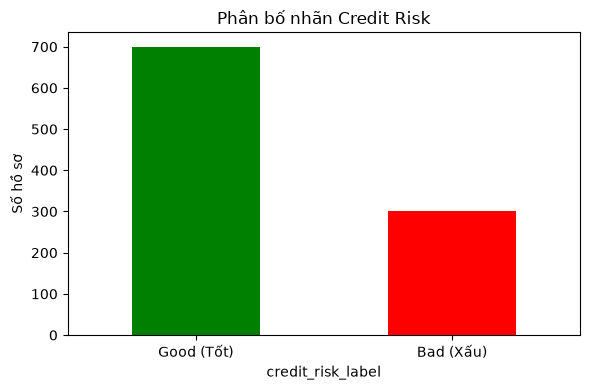

In [4]:
# VẤN ĐỀ 1: Mất cân bằng lớp
import matplotlib.pyplot as plt

print("=== VẤN ĐỀ 1: Mất cân bằng lớp ===")
counts = df['credit_risk_label'].value_counts()
print(f"Số lượng: Good = {counts['Good']}, Bad = {counts['Bad']}")
print(f"Tỷ lệ: Good = {counts['Good']/len(df):.1%}, Bad = {counts['Bad']/len(df):.1%}")
print(f"Tỷ lệ mất cân bằng: {counts['Good']/counts['Bad']:.1f}:1")
print("\nHẬU QUẢ: Nếu đoán tất cả là 'Good', Accuracy = 70% nhưng bỏ sót 100% người Xấu.")
print("→ Không dùng Accuracy, phải dùng Cost-based metric 5:1.")

# Vẽ biểu đồ
fig, ax = plt.subplots(figsize=(6, 4))
counts.plot(kind='bar', color=['green', 'red'], ax=ax)
ax.set_title('Phân bố nhãn Credit Risk')
ax.set_ylabel('Số hồ sơ')
ax.set_xticklabels(['Good (Tốt)', 'Bad (Xấu)'], rotation=0)
plt.tight_layout()
plt.show()

In [5]:
# VẤN ĐỀ 2: Kiểm tra giá trị bất khả thi
print("=== VẤN ĐỀ 2: Giá trị bất khả thi ===")

# Kiểm tra các giá trị không hợp lý
checks = {
    'duration <= 0': (df['duration'] <= 0).sum(),
    'credit_amount <= 0': (df['credit_amount'] <= 0).sum(),
    'age < 18': (df['age'] < 18).sum(),
    'installment_commitment ngoài 1-4': ((df['installment_commitment'] < 1) | (df['installment_commitment'] > 4)).sum(),
    'num_dependents < 0': (df['num_dependents'] < 0).sum(),
}

for check, count in checks.items():
    status = "✓ OK" if count == 0 else f"⚠ CÓ {count} dòng"
    print(f"  {check}: {count} dòng {status}")

print("\nHẬU QUẢ: Nếu có giá trị bất khả thi, mô hình sẽ học sai quy luật.")
print("→ Cần kiểm tra và xử lý trước khi huấn luyện.")

=== VẤN ĐỀ 2: Giá trị bất khả thi ===
  duration <= 0: 0 dòng ✓ OK
  credit_amount <= 0: 0 dòng ✓ OK
  age < 18: 0 dòng ✓ OK
  installment_commitment ngoài 1-4: 0 dòng ✓ OK
  num_dependents < 0: 0 dòng ✓ OK

HẬU QUẢ: Nếu có giá trị bất khả thi, mô hình sẽ học sai quy luật.
→ Cần kiểm tra và xử lý trước khi huấn luyện.


=== VẤN ĐỀ 3: Outlier ===
  credit_amount: Q1=1365.5, Q3=3972.2, IQR=2606.8, outlier=72 dòng (7.2%)
  duration: Q1=12.0, Q3=24.0, IQR=12.0, outlier=70 dòng (7.0%)
  age: Q1=27.0, Q3=42.0, IQR=15.0, outlier=23 dòng (2.3%)

HẬU QUẢ: Outlier làm lệch hệ số Logistic Regression, đặc biệt với credit_amount.
→ Sẽ dùng StandardScaler và cân nhắc log-transform cho credit_amount.


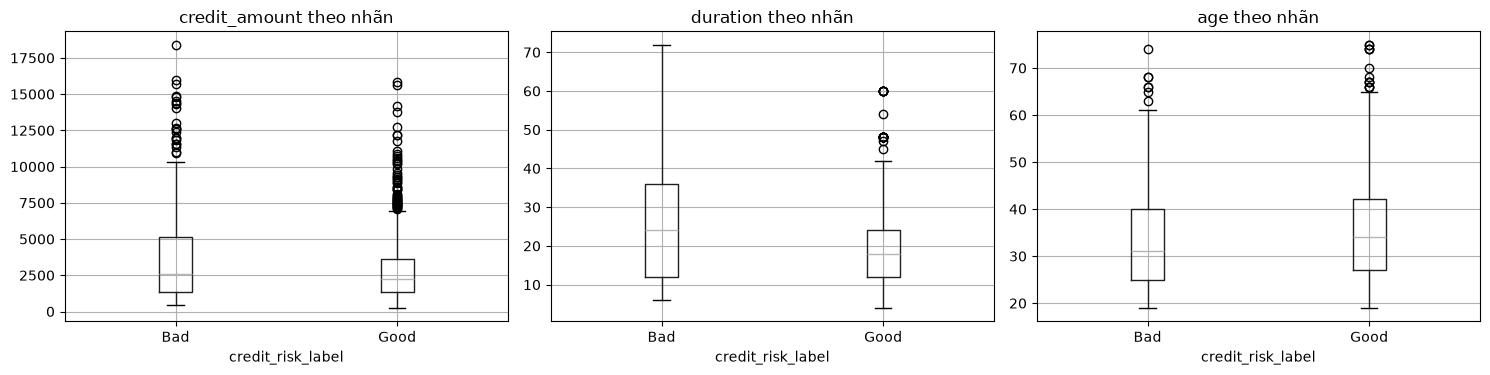

In [6]:
# VẤN ĐỀ 3: Outlier ở credit_amount và duration
print("=== VẤN ĐỀ 3: Outlier ===")

for col in ['credit_amount', 'duration', 'age']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"  {col}: Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}, outlier={outliers} dòng ({outliers/len(df):.1%})")

print("\nHẬU QUẢ: Outlier làm lệch hệ số Logistic Regression, đặc biệt với credit_amount.")
print("→ Sẽ dùng StandardScaler và cân nhắc log-transform cho credit_amount.")

# Vẽ boxplot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['credit_amount', 'duration', 'age']):
    df.boxplot(column=col, by='credit_risk_label', ax=ax)
    ax.set_title(f'{col} theo nhãn')
plt.suptitle('')
plt.tight_layout()
plt.show()

In [7]:
# VẤN ĐỀ 4 (bonus): Mã hóa khó hiểu
print("=== VẤN ĐỀ 4: Mã hóa A11-A14 khó hiểu ===")
print("Dữ liệu gốc dùng mã A11, A12... không thể giải thích cho khách hàng.")
print("Ví dụ: Nếu mô hình từ chối vì 'checking_status = A11',")
print("khách hàng không hiểu. Phải map sang '< 0 DM' mới giải thích được.")
print("\n→ ĐÃ XỬ LÝ bằng cell map nhãn ở trên (tạo cột _label).")
print("→ Cần thiết cho 'thông báo từ chối' ở cuối đồ án.")


=== VẤN ĐỀ 4: Mã hóa A11-A14 khó hiểu ===
Dữ liệu gốc dùng mã A11, A12... không thể giải thích cho khách hàng.
Ví dụ: Nếu mô hình từ chối vì 'checking_status = A11',
khách hàng không hiểu. Phải map sang '< 0 DM' mới giải thích được.

→ ĐÃ XỬ LÝ bằng cell map nhãn ở trên (tạo cột _label).
→ Cần thiết cho 'thông báo từ chối' ở cuối đồ án.
